# Abiha | Radiation-induced vacancies: Phase 1

**Research workflow:** audit the source workbook, establish eight independent material–energy profiles, hold out complete energies, and compare a multi-output MLP with a simple energy-interpolation baseline.

**Interpretation safeguards:** Two Pb-containing sheet titles say `CsPbI9` (50 and 500 keV). The original notebook treated them as `CsPbI3`; that identification is **provisional until checked with the simulation source**. Vacancy normalization, fluence and physical units have not been verified. These are *reported vacancy values*, not automatically vacancies per cubic centimeter. All models use the original numbers without claiming experimental measurement or device lifetime.

Running this notebook requires the supplied Excel workbook and Python packages `pandas`, `openpyxl`, `numpy`, `scipy`, `scikit-learn`, `tensorflow`, and `matplotlib`. The first cell searches the working directory (including `upload/`) for the workbook; on Colab, upload the file using the Files sidebar.

In [1]:
from pathlib import Path
import re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

SEED = 42
np.random.seed(SEED)
paths = sorted(Path('.').rglob('Lumiere Research Data Analaysis*.xlsx'))
if not paths:
    raise FileNotFoundError('Upload Lumiere Research Data Analaysis.xlsx into the current notebook folder or its upload/ subfolder.')
file_path = paths[0]
print('Source workbook:', file_path.resolve())

Source workbook: C:\Users\waqar\OneDrive\Desktop\abihas mlp\Lumiere Research Data Analaysis.xlsx


In [2]:
xls = pd.ExcelFile(file_path)
records, audit = [], []
for sheet in xls.sheet_names:
    raw = pd.read_excel(xls, sheet_name=sheet, header=None)
    title = str(raw.iat[0, 0]).strip()
    match = re.search(r'(20|50|100|500)\s*keV', title, re.IGNORECASE)
    if not match:
        raise ValueError(f'Energy missing from {sheet}: {title}')
    energy = int(match.group(1))
    material = 'Cs3Sb2I9' if 'Sb' in title else 'CsPbI3'
    # Numeric observations follow four header/spacer rows.
    numeric = raw.iloc[4:, :4].apply(pd.to_numeric, errors='coerce')
    numeric = numeric.loc[numeric.iloc[:, 0].notna()].copy()
    numeric.columns = ['depth_angstrom', 'vac_Cs', 'vac_B', 'vac_I']
    if numeric[['vac_Cs', 'vac_B', 'vac_I']].isna().any().any():
        raise ValueError(f'Missing target data: {sheet}')
    if (numeric[['vac_Cs', 'vac_B', 'vac_I']] < 0).any().any():
        raise ValueError(f'Negative vacancy values: {sheet}')
    if numeric['depth_angstrom'].duplicated().any():
        raise ValueError(f'Duplicate depths: {sheet}')
    numeric['energy_keV'] = energy
    numeric['material'] = material
    numeric['source_sheet'] = sheet
    numeric['original_label'] = title
    numeric['material_identity_unverified'] = ('CsPbI9' in title)
    numeric['profile_id'] = material + '_' + str(energy) + 'keV'
    records.append(numeric)
    audit.append(dict(sheet=sheet, original_label=title, interpreted_material=material,
                      energy_keV=energy, n_rows=len(numeric),
                      min_depth=numeric.depth_angstrom.min(), max_depth=numeric.depth_angstrom.max(),
                      needs_material_confirmation=('CsPbI9' in title)))
df = pd.concat(records, ignore_index=True)
audit_df = pd.DataFrame(audit)
assert len(df) == 796 and df.profile_id.nunique() == 8
assert set(df.energy_keV.unique()) == {20, 50, 100, 500}
assert not df.duplicated(['material', 'energy_keV', 'depth_angstrom']).any()
display(audit_df)
print('Total rows:', len(df), '| Distinct profiles:', df.profile_id.nunique())

,sheet,original_label,interpreted_material,energy_keV,n_rows,min_depth,max_depth,needs_material_confirmation
0,Sheet1,CsPbI3 in 20 keV,CsPbI3,20,100,100.01,10000.00,False
1,Sheet2,CsPbI9 in 50 keV,CsPbI3,50,100,100.01,10000.00,True
2,Sheet3,CsPbI3 in 100 keV,CsPbI3,100,96,100.01,9600.01,False
3,Sheet4,CsPbI9 in 500 keV,CsPbI3,500,100,100.01,10000.00,True
4,Sheet5,Cs3Sb2I9 in 20 keV,Cs3Sb2I9,20,100,100.01,10000.00,False
5,Sheet6,Cs3Sb2I9 in 50 keV,Cs3Sb2I9,50,100,100.01,10000.00,False
6,Sheet7,Cs3Sb2I9 in 100 keV,Cs3Sb2I9,100,100,100.01,10000.00,False
7,Sheet8,Cs3Sb2I9 in 500 keV,Cs3Sb2I9,500,100,100.01,10000.00,False


Total rows: 796 | Distinct profiles: 8


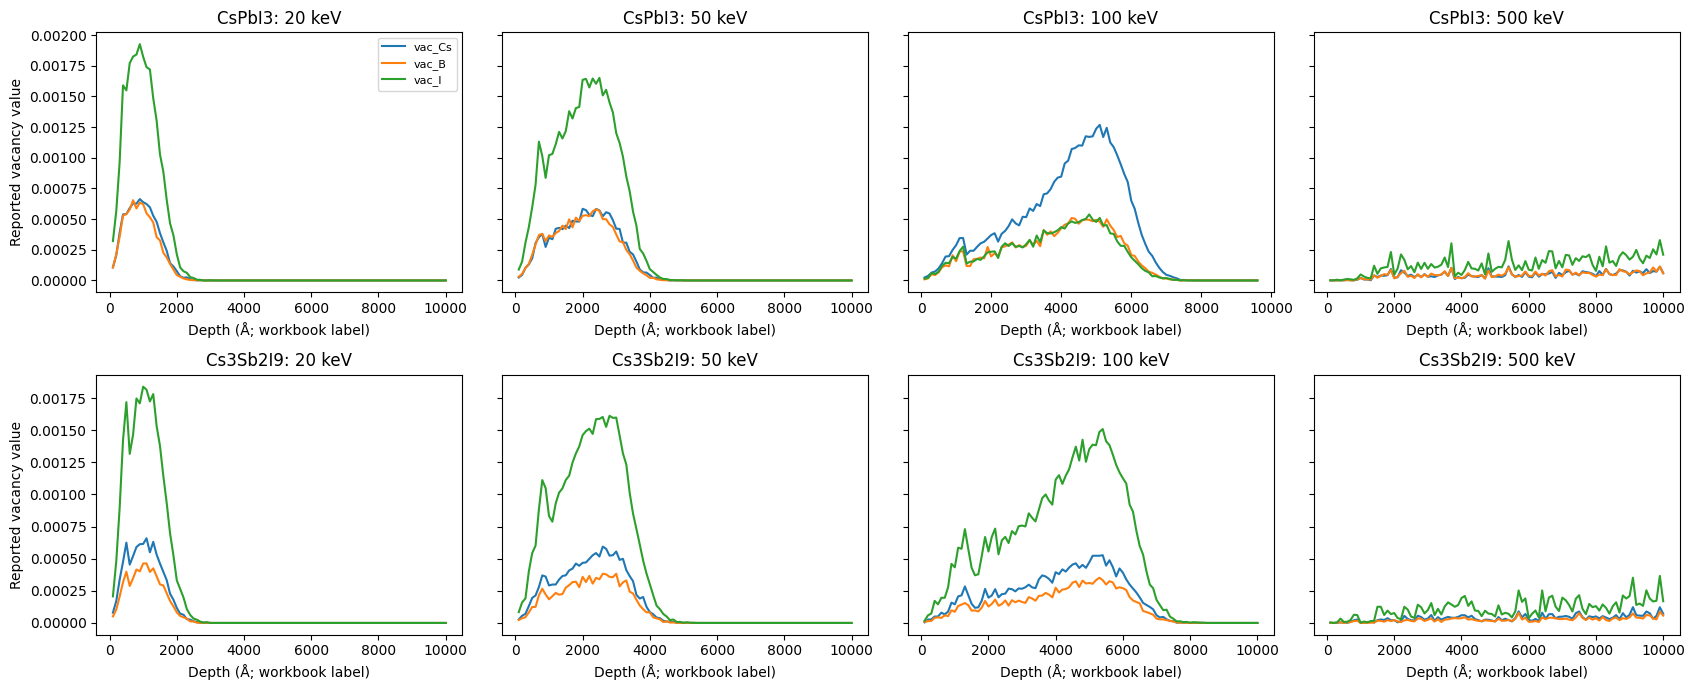

In [3]:
# Original source remains untouched; these exports retain sheet-level provenance.
df.to_csv('Abiha_clean_profiles_provisional.csv', index=False)
audit_df.to_csv('Abiha_source_audit.csv', index=False)
fig, axes = plt.subplots(2, 4, figsize=(17, 7), sharey='row')
for i, material in enumerate(['CsPbI3', 'Cs3Sb2I9']):
    for j, energy in enumerate([20, 50, 100, 500]):
        ax = axes[i, j]
        part = df.loc[(df.material == material) & (df.energy_keV == energy)].sort_values('depth_angstrom')
        for column in ['vac_Cs', 'vac_B', 'vac_I']:
            ax.plot(part.depth_angstrom, part[column], label=column)
        ax.set_title(f'{material}: {energy} keV')
        ax.set_xlabel('Depth (Å; workbook label)')
        if j == 0: ax.set_ylabel('Reported vacancy value')
axes[0, 0].legend(fontsize=8)
plt.tight_layout()
plt.savefig('Abiha_original_profiles.png', dpi=250)
plt.show()

## Leakage-free held-out-energy MLP

For each test energy, *both* materials at that energy are excluded. Within the other three energies, one energy is reserved for early-stopping validation; after selecting an epoch count the model is refit on **all three outer-training energies**. Input and target scalers are refit using only the relevant training rows. Each test profile is evaluated once. The two outer energies 20 and 500 keV are extrapolation, not interpolation.

There are only eight independent profiles. The 796 depth rows are correlated, so results should be reported per material × energy × vacancy species; repeated seeds measure optimization variability, not full prediction uncertainty.

In [4]:
try:
    import tensorflow as tf
except ImportError as exc:
    raise ImportError('Install TensorFlow (`pip install tensorflow`) or run in Google Colab.') from exc
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score
from scipy.interpolate import interp1d

FEATURES = ['energy_keV', 'depth_angstrom']
TARGETS = ['vac_Cs', 'vac_B', 'vac_I']
ENERGIES = [20, 50, 100, 500]
MATERIALS = ['CsPbI3', 'Cs3Sb2I9']

def encode_features(frame):
    return np.column_stack([frame[FEATURES].to_numpy(dtype=float),
                            (frame.material == 'CsPbI3').to_numpy(dtype=float),
                            (frame.material == 'Cs3Sb2I9').to_numpy(dtype=float)])

def new_model(seed):
    tf.keras.utils.set_random_seed(seed)
    net = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(4,)),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dense(64, activation='relu'),
        tf.keras.layers.Dense(32, activation='relu'),
        tf.keras.layers.Dense(3)
    ])
    net.compile(optimizer=tf.keras.optimizers.Adam(0.001), loss='mse')
    return net

def mlp_outer_fold(outer_energy, seed=42):
    outer_train = df.loc[df.energy_keV != outer_energy].copy()
    test = df.loc[df.energy_keV == outer_energy].copy()
    # Fixed, predeclared validation rule; no test-set selection.
    val_energy = sorted(set(ENERGIES) - {outer_energy})[1]
    fit = outer_train.loc[outer_train.energy_keV != val_energy]
    val = outer_train.loc[outer_train.energy_keV == val_energy]
    xs, ys = StandardScaler(), StandardScaler()
    a = xs.fit_transform(encode_features(fit))
    b = xs.transform(encode_features(val))
    ya = ys.fit_transform(fit[TARGETS])
    yb = ys.transform(val[TARGETS])
    trial = new_model(seed)
    history = trial.fit(a, ya, validation_data=(b, yb), epochs=500,
                        batch_size=32, verbose=0,
                        callbacks=[tf.keras.callbacks.EarlyStopping(
                            monitor='val_loss', patience=35, restore_best_weights=True)])
    best_epoch = int(np.argmin(history.history['val_loss']) + 1)
    xs_all, ys_all = StandardScaler(), StandardScaler()
    x_all = xs_all.fit_transform(encode_features(outer_train))
    y_all = ys_all.fit_transform(outer_train[TARGETS])
    final = new_model(seed)
    final.fit(x_all, y_all, epochs=best_epoch, batch_size=32, verbose=0)
    prediction = ys_all.inverse_transform(final.predict(xs_all.transform(encode_features(test)), verbose=0))
    return test.reset_index(drop=True), prediction, best_epoch, val_energy

## Simple profile-based energy baseline

Each training vacancy profile is linearly interpolated **within its observed depth support**, separately for each material and species. The predictions are then linearly interpolated between neighboring energies, or extrapolated beyond the observed range. Values at test depths outside the intersection of required source-profile depth supports are labeled `NaN` and excluded from *both* methods' paired-comparison metrics. This avoids silently treating depth extrapolation as known data.

In [5]:
def baseline_predictions(train, test):
    out = np.full((len(test), len(TARGETS)), np.nan)
    for material in MATERIALS:
        idx = np.flatnonzero((test.material == material).to_numpy())
        if not len(idx): continue
        subset = test.iloc[idx]
        available = sorted(train.loc[train.material == material, 'energy_keV'].unique())
        energy = float(subset.energy_keV.iloc[0])
        lo, hi = (available[:2] if energy < available[0] else
                  available[-2:] if energy > available[-1] else
                  (max(e for e in available if e < energy), min(e for e in available if e > energy)))
        z = subset.depth_angstrom.to_numpy(dtype=float)
        y_by_energy = []
        for e in [lo, hi]:
            p = train.loc[(train.material == material) & (train.energy_keV == e)].sort_values('depth_angstrom')
            f = interp1d(p.depth_angstrom.to_numpy(), p[TARGETS].to_numpy(),
                         axis=0, bounds_error=False, fill_value=np.nan)
            y_by_energy.append(f(z))
        out[idx] = y_by_energy[0] + (energy - lo) / (hi - lo) * (y_by_energy[1] - y_by_energy[0])
    return out

def score_rows(frame, actual, mlp, baseline, seed, epoch, val_energy):
    rows = []
    for material in MATERIALS:
        m = (frame.material == material).to_numpy()
        for k, target in enumerate(TARGETS):
            # Comparable support for the baseline and MLP.
            valid = m & np.isfinite(baseline[:, k])
            for method, estimate in [('MLP', mlp[:, k]), ('Linear energy baseline', baseline[:, k])]:
                ytrue, yhat = actual[valid, k], estimate[valid]
                rows.append(dict(test_energy_keV=int(frame.energy_keV.iloc[0]),
                                 evaluation='extrapolation' if int(frame.energy_keV.iloc[0]) in (20, 500) else 'interpolation',
                                 material=material, species=target, method=method, seed=seed,
                                 n_evaluated=len(ytrue), MAE=mean_absolute_error(ytrue, yhat),
                                 RMSE=np.sqrt(mean_squared_error(ytrue, yhat)),
                                 R2=r2_score(ytrue, yhat) if len(ytrue) >= 2 else np.nan,
                                 chosen_epoch=epoch, validation_energy_keV=val_energy))
    return rows

results, predictions = [], []
for held_out in ENERGIES:
    train = df.loc[df.energy_keV != held_out].copy()
    for seed in [42, 43, 44, 45, 46]:
        test, yhat, epoch, val_energy = mlp_outer_fold(held_out, seed)
        baseline = baseline_predictions(train, test)
        actual = test[TARGETS].to_numpy()
        results.extend(score_rows(test, actual, yhat, baseline, seed, epoch, val_energy))
        p = test[['material', 'energy_keV', 'depth_angstrom', 'profile_id']].copy()
        p['seed'] = seed
        for k, target in enumerate(TARGETS):
            p[target + '_actual'] = actual[:, k]
            p[target + '_MLP'] = yhat[:, k]
            p[target + '_baseline'] = baseline[:, k]
        predictions.append(p)
        print(f'Finished held-out {held_out} keV / seed {seed} / epoch {epoch}')

metric_df = pd.DataFrame(results)
pred_df = pd.concat(predictions, ignore_index=True)
metric_df.to_csv('Abiha_heldout_metrics.csv', index=False)
pred_df.to_csv('Abiha_heldout_predictions.csv', index=False)
display(metric_df.groupby(['test_energy_keV', 'material', 'species', 'method'])[['MAE', 'RMSE', 'R2']].agg(['mean', 'std']).round(7))

Finished held-out 20 keV / seed 42 / epoch 3
Finished held-out 20 keV / seed 43 / epoch 2
Finished held-out 20 keV / seed 44 / epoch 3
Finished held-out 20 keV / seed 45 / epoch 4
Finished held-out 20 keV / seed 46 / epoch 3
Finished held-out 50 keV / seed 42 / epoch 1
Finished held-out 50 keV / seed 43 / epoch 2
Finished held-out 50 keV / seed 44 / epoch 2
Finished held-out 50 keV / seed 45 / epoch 2
Finished held-out 50 keV / seed 46 / epoch 1
Finished held-out 100 keV / seed 42 / epoch 6
Finished held-out 100 keV / seed 43 / epoch 5
Finished held-out 100 keV / seed 44 / epoch 5
Finished held-out 100 keV / seed 45 / epoch 6
Finished held-out 100 keV / seed 46 / epoch 5
Finished held-out 500 keV / seed 42 / epoch 154
Finished held-out 500 keV / seed 43 / epoch 94
Finished held-out 500 keV / seed 44 / epoch 74
Finished held-out 500 keV / seed 45 / epoch 334
Finished held-out 500 keV / seed 46 / epoch 121


MAE            \
                                                             mean       std   
test_energy_keV material species method                                       
20              Cs3Sb2I9 vac_B   Linear energy baseline  0.000138  0.000000   
                                 MLP                     0.000102  0.000005   
                         vac_Cs  Linear energy baseline  0.000204  0.000000   
                                 MLP                     0.000156  0.000008   
                         vac_I   Linear energy baseline  0.000593  0.000000   
                                 MLP                     0.000449  0.000014   
                CsPbI3   vac_B   Linear energy baseline  0.000197  0.000000   
                                 MLP                     0.000151  0.000009   
                         vac_Cs  Linear energy baseline  0.000286  0.000000   
                                 MLP                     0.000219  0.000017   
                         vac_I   Linear energy baseline  0.000511  0.000000   
                                 MLP                     0.000360  0.000019   
50              Cs3Sb2I9 vac_B   Linear energy baseline  0.000086  0.000000   
                                 MLP                     0.000091  0.000010   
                         vac_Cs  Linear energy baseline  0.000128  0.000000   
                                 MLP                     0.000131  0.000006   
                         vac_I   Linear energy baseline  0.000371  0.000000   
                                 MLP                     0.000387  0.000032   
                CsPbI3   vac_B   Linear energy baseline  0.000123  0.000000   
                                 MLP                     0.000135  0.000012   
                         vac_Cs  Linear energy baseline  0.000179  0.000000   
                                 MLP                     0.000160  0.000006   
                         vac_I   Linear energy baseline  0.000320  0.000000   
                                 MLP                     0.000377  0.000031   
100             Cs3Sb2I9 vac_B   Linear energy baseline  0.000117  0.000000   
                                 MLP                     0.000108  0.000003   
                         vac_Cs  Linear energy baseline  0.000173  0.000000   
                                 MLP                     0.000161  0.000004   
                         vac_I   Linear energy baseline  0.000508  0.000000   
                                 MLP                     0.000473  0.000015   
                CsPbI3   vac_B   Linear energy baseline  0.000173  0.000000   
                                 MLP                     0.000156  0.000004   
                         vac_Cs  Linear energy baseline  0.000329  0.000000   
                                 MLP                     0.000345  0.000006   
                         vac_I   Linear energy baseline  0.000387  0.000000   
                                 MLP                     0.000294  0.000015   
500             Cs3Sb2I9 vac_B   Linear energy baseline  0.001049  0.000000   
                                 MLP                     0.000414  0.000448   
                         vac_Cs  Linear energy baseline  0.001561  0.000000   
                                 MLP                     0.000478  0.000161   
                         vac_I   Linear energy baseline  0.004574  0.000000   
                                 MLP                     0.001995  0.002306   
                CsPbI3   vac_B   Linear energy baseline  0.001558  0.000000   
                                 MLP                     0.000409  0.000453   
                         vac_Cs  Linear energy baseline  0.002965  0.000000   
                                 MLP                     0.000709  0.000194   
                         vac_I   Linear energy baseline  0.003485  0.000000   
                                 MLP                     0.002625  0.002449   

                                

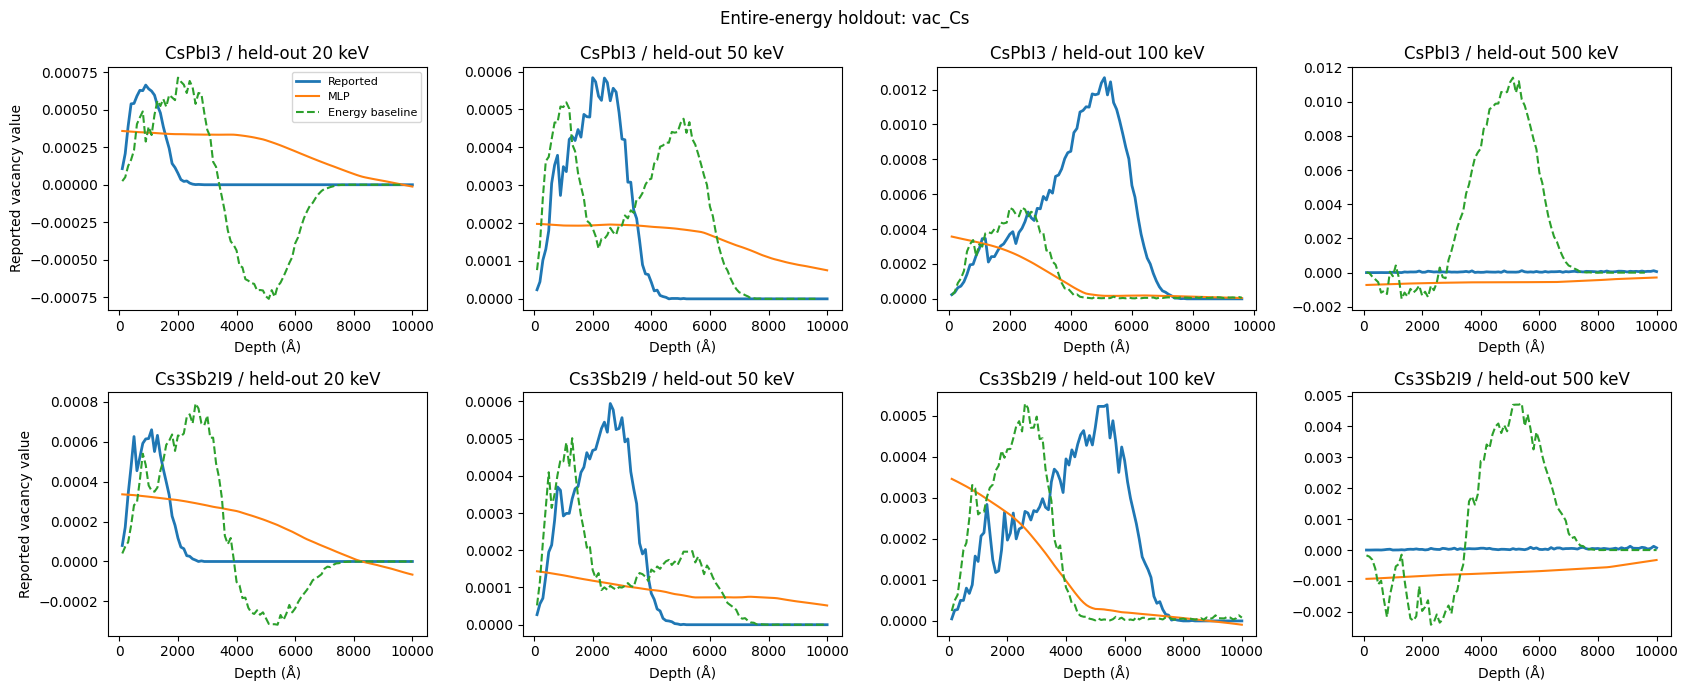

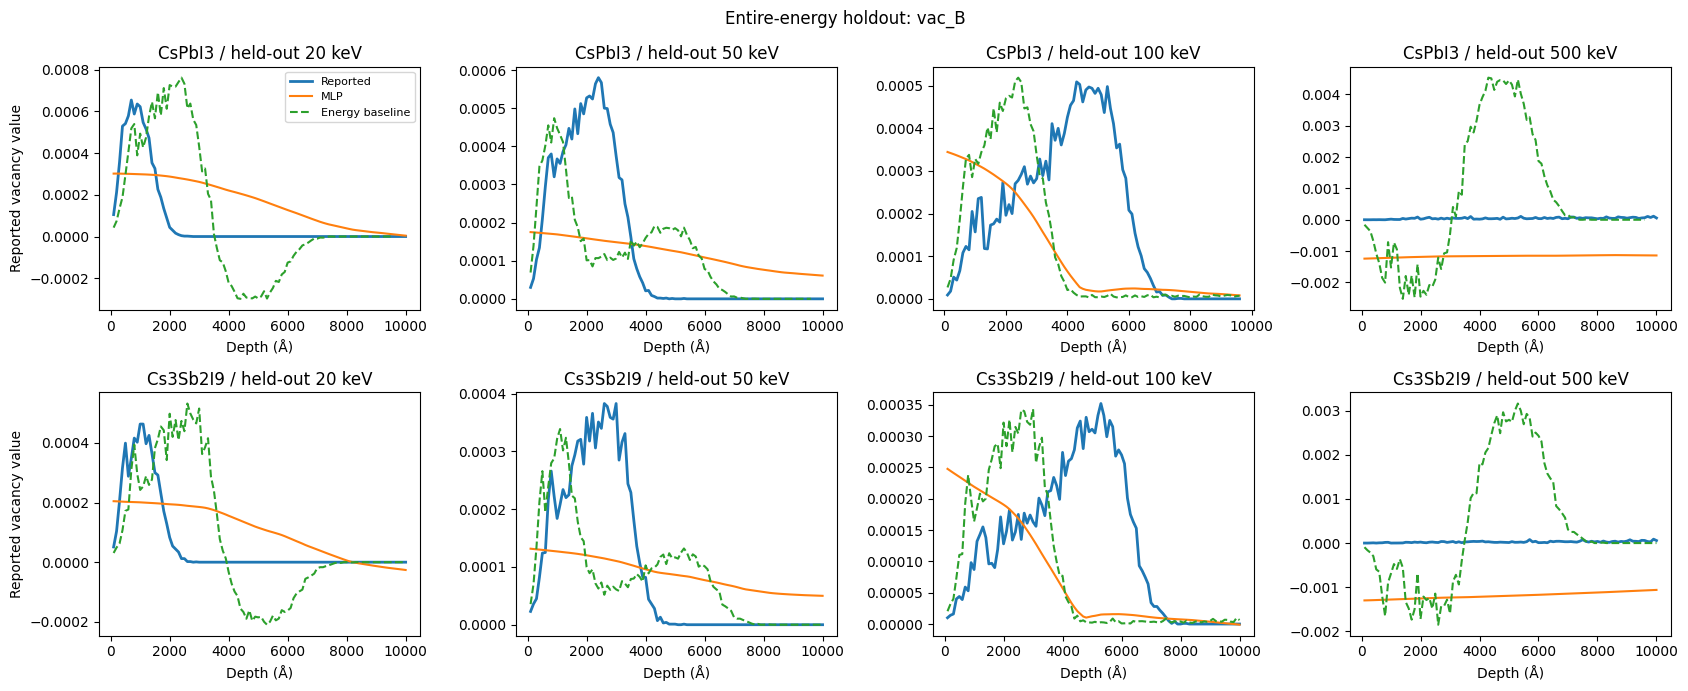

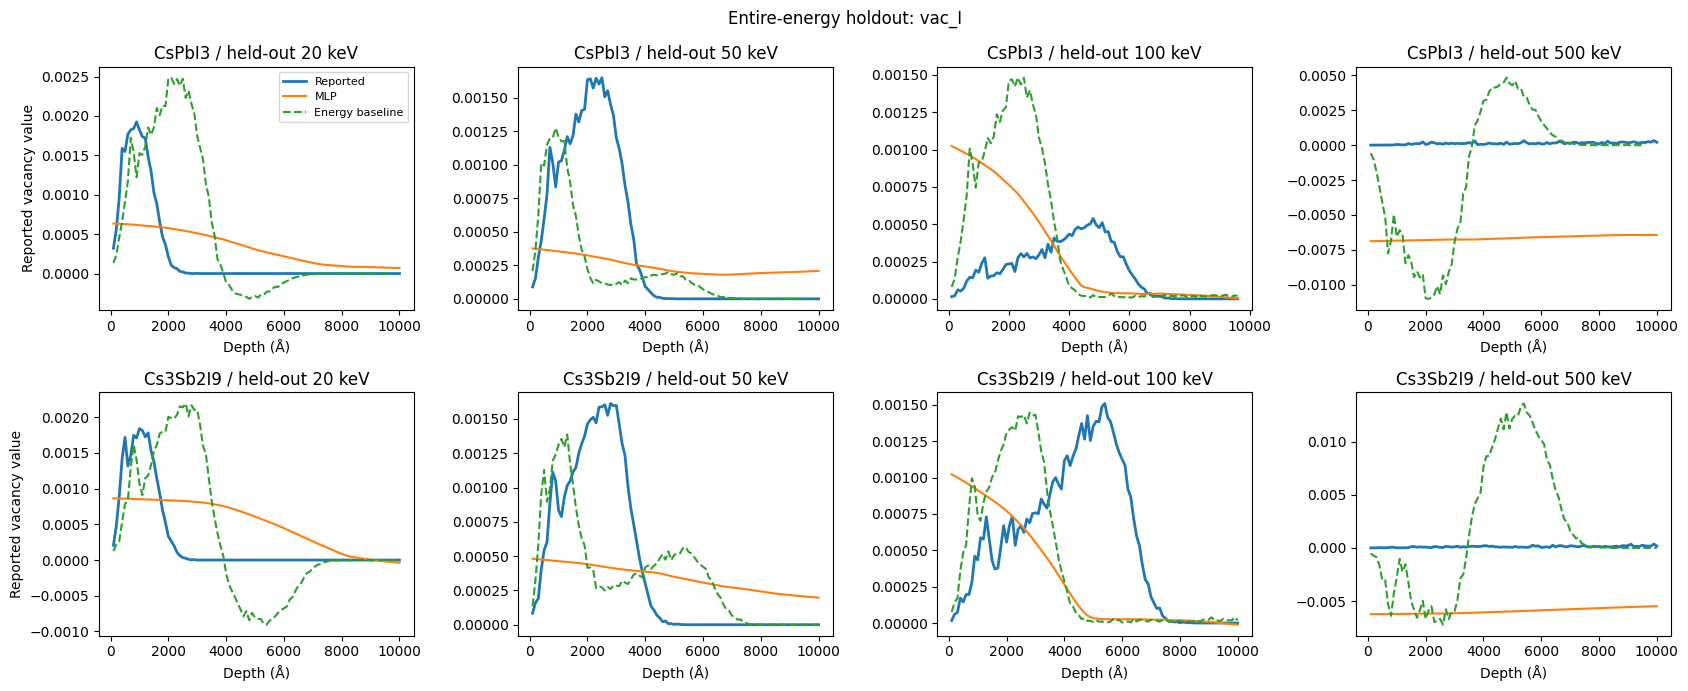

In [6]:
# Inspect one representative optimization seed, with one panel per held-out energy.
for species in TARGETS:
    fig, axes = plt.subplots(2, 4, figsize=(17, 7))
    for i, material in enumerate(MATERIALS):
        for j, energy in enumerate(ENERGIES):
            panel = pred_df.loc[(pred_df.material == material) &
                                (pred_df.energy_keV == energy) & (pred_df.seed == 42)].sort_values('depth_angstrom')
            ax = axes[i, j]
            z = panel.depth_angstrom
            ax.plot(z, panel[species + '_actual'], label='Reported', lw=2)
            ax.plot(z, panel[species + '_MLP'], label='MLP', lw=1.5)
            ax.plot(z, panel[species + '_baseline'], label='Energy baseline', ls='--')
            ax.set_title(f'{material} / held-out {energy} keV')
            ax.set_xlabel('Depth (Å)')
            if j == 0: ax.set_ylabel('Reported vacancy value')
    axes[0, 0].legend(fontsize=8)
    fig.suptitle(f'Entire-energy holdout: {species}')
    plt.tight_layout()
    plt.savefig(f'Abiha_heldout_{species}.png', dpi=250)
    plt.show()

In [7]:

import numpy as np
import pandas as pd
import tensorflow as tf
import matplotlib.pyplot as plt

from scipy.interpolate import interp1d
from sklearn.preprocessing import StandardScaler
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

ENERGIES = [20, 50, 100, 500]
MATERIALS = ["CsPbI3", "Cs3Sb2I9"]
TARGETS = ["vac_Cs", "vac_B", "vac_I"]
SEEDS = [42, 43, 44, 45, 46]

# Confirm that the source data is available
assert df["profile_id"].nunique() == 8
assert set(df["energy_keV"].unique()) == set(ENERGIES)

def make_features(frame):
    energy = np.log10(frame["energy_keV"].to_numpy(dtype=float))
    depth = frame["depth_angstrom"].to_numpy(dtype=float)

    pb = (frame["material"] == "CsPbI3").astype(float).to_numpy()
    sb = (frame["material"] == "Cs3Sb2I9").astype(float).to_numpy()

    return np.column_stack([energy, depth, pb, sb])

def source_profile(train, material, energy, depths):
    part = train[
        (train["material"] == material) &
        (train["energy_keV"] == energy)
    ].sort_values("depth_angstrom")

    interpolation = interp1d(
        part["depth_angstrom"].to_numpy(),
        part[TARGETS].to_numpy(),
        axis=0,
        bounds_error=False,
        fill_value=np.nan
    )

    return interpolation(depths)

def calculate_baselines(train, test):
    n = len(test)

    zero = np.zeros((n, 3))
    nearest = np.full((n, 3), np.nan)
    linear = np.full((n, 3), np.nan)

    for material in MATERIALS:
        mask = (test["material"] == material).to_numpy()
        indices = np.flatnonzero(mask)

        if len(indices) == 0:
            continue

        subset = test.iloc[indices]
        energy = float(subset["energy_keV"].iloc[0])
        depths = subset["depth_angstrom"].to_numpy()

        available = sorted(
            train.loc[
                train["material"] == material,
                "energy_keV"
            ].unique()
        )

        # Baseline 1: nearest known energy
        nearest_energy = min(
            available,
            key=lambda e: abs(e - energy)
        )

        nearest[indices] = source_profile(
            train, material, nearest_energy, depths
        )

        # Baseline 2: linear energy interpolation/extrapolation
        if energy < available[0]:
            low, high = available[:2]
        elif energy > available[-1]:
            low, high = available[-2:]
        else:
            low = max(e for e in available if e < energy)
            high = min(e for e in available if e > energy)

        y_low = source_profile(train, material, low, depths)
        y_high = source_profile(train, material, high, depths)

        weight = (energy - low) / (high - low)
        linear[indices] = y_low + weight * (y_high - y_low)

    return {
        "Zero baseline": zero,
        "Nearest energy": nearest,
        "Linear energy": linear
    }

print("Preprocessing and baselines ready.")


Preprocessing and baselines ready.


In [8]:

def build_improved_mlp(seed):
    tf.keras.utils.set_random_seed(seed)

    model = tf.keras.Sequential([
        tf.keras.layers.Input(shape=(4,)),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(64, activation="relu"),
        tf.keras.layers.Dense(32, activation="relu"),
        tf.keras.layers.Dense(3, activation="softplus")
    ])

    model.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=0.001),
        loss="mse"
    )

    return model


def train_improved_fold(test_energy, seed):
    train_all = df[df["energy_keV"] != test_energy].copy()
    test = df[df["energy_keV"] == test_energy].copy()

    # Choose validation energy without inspecting test results
    remaining = sorted(set(ENERGIES) - {test_energy})
    val_energy = remaining[1]

    train_fit = train_all[
        train_all["energy_keV"] != val_energy
    ].copy()

    validation = train_all[
        train_all["energy_keV"] == val_energy
    ].copy()

    # First stage: determine training duration
    x_scaler = StandardScaler()

    X_fit = x_scaler.fit_transform(
        make_features(train_fit)
    )

    X_val = x_scaler.transform(
        make_features(validation)
    )

    y_fit_raw = train_fit[TARGETS].to_numpy()
    y_val_raw = validation[TARGETS].to_numpy()

    # Per-species scale learned ONLY from fitting data
    y_scale = np.maximum(
        np.percentile(y_fit_raw, 95, axis=0),
        1e-9
    )

    y_fit = y_fit_raw / y_scale
    y_val = y_val_raw / y_scale

    model = build_improved_mlp(seed)

    history = model.fit(
        X_fit,
        y_fit,
        validation_data=(X_val, y_val),
        epochs=500,
        batch_size=32,
        verbose=0,
        callbacks=[
            tf.keras.callbacks.EarlyStopping(
                monitor="val_loss",
                patience=35,
                restore_best_weights=True
            )
        ]
    )

    best_epoch = int(
        np.argmin(history.history["val_loss"]) + 1
    )

    # Second stage: refit on ALL three training energies
    final_x_scaler = StandardScaler()

    X_train = final_x_scaler.fit_transform(
        make_features(train_all)
    )

    X_test = final_x_scaler.transform(
        make_features(test)
    )

    y_train_raw = train_all[TARGETS].to_numpy()

    final_y_scale = np.maximum(
        np.percentile(y_train_raw, 95, axis=0),
        1e-9
    )

    y_train = y_train_raw / final_y_scale

    final_model = build_improved_mlp(seed)

    final_model.fit(
        X_train,
        y_train,
        epochs=best_epoch,
        batch_size=32,
        verbose=0
    )

    predictions = (
        final_model.predict(X_test, verbose=0)
        * final_y_scale
    )

    return (
        test.reset_index(drop=True),
        predictions,
        train_all,
        best_epoch
    )

print("Improved MLP ready.")


Improved MLP ready.


In [9]:

results = []
all_predictions = []

for test_energy in ENERGIES:
    print(f"\nTesting unseen energy: {test_energy} keV")

    for seed in SEEDS:
        test, mlp_pred, train, best_epoch = train_improved_fold(
            test_energy, seed
        )

        baselines = calculate_baselines(train, test)

        predictions = {
            "Improved MLP": mlp_pred,
            **baselines
        }

        actual = test[TARGETS].to_numpy()

        output = test[
            ["material", "energy_keV",
             "depth_angstrom", "profile_id"]
        ].copy()

        output["seed"] = seed

        for k, species in enumerate(TARGETS):
            output[f"{species}_actual"] = actual[:, k]

            for model_name, pred in predictions.items():
                output[
                    f"{species}_{model_name.replace(' ', '_')}"
                ] = pred[:, k]

        all_predictions.append(output)

        for material in MATERIALS:
            material_mask = (
                test["material"] == material
            ).to_numpy()

            for k, species in enumerate(TARGETS):

                # Same supported depth points for every model
                valid = material_mask.copy()

                for pred in predictions.values():
                    valid &= np.isfinite(pred[:, k])

                y_true = actual[valid, k]

                if len(y_true) < 2:
                    raise ValueError(
                        f"Insufficient common depth support: "
                        f"{material}, {test_energy}, {species}"
                    )

                for model_name, pred in predictions.items():
                    y_pred = pred[valid, k]

                    results.append({
                        "energy_keV": test_energy,
                        "material": material,
                        "species": species,
                        "model": model_name,
                        "seed": seed,
                        "n_evaluated": len(y_true),
                        "best_epoch": best_epoch,
                        "MAE": mean_absolute_error(y_true, y_pred),
                        "RMSE": np.sqrt(
                            mean_squared_error(y_true, y_pred)
                        ),
                        "R2": r2_score(y_true, y_pred),
                        "negative_fraction": np.mean(y_pred < 0)
                    })

        print(
            f"  Seed {seed} completed "
            f"(selected epoch: {best_epoch})"
        )

results_df = pd.DataFrame(results)
predictions_df = pd.concat(
    all_predictions, ignore_index=True
)

results_df.to_csv(
    "Abiha_Experiment2_Metrics.csv",
    index=False
)

predictions_df.to_csv(
    "Abiha_Experiment2_Predictions.csv",
    index=False
)

print("\nAll experiments completed.")
print("Results saved successfully.")



Testing unseen energy: 20 keV
  Seed 42 completed (selected epoch: 2)
  Seed 43 completed (selected epoch: 2)
  Seed 44 completed (selected epoch: 2)
  Seed 45 completed (selected epoch: 1)
  Seed 46 completed (selected epoch: 2)

Testing unseen energy: 50 keV
  Seed 42 completed (selected epoch: 2)
  Seed 43 completed (selected epoch: 1)
  Seed 44 completed (selected epoch: 2)
  Seed 45 completed (selected epoch: 1)
  Seed 46 completed (selected epoch: 2)

Testing unseen energy: 100 keV
  Seed 42 completed (selected epoch: 9)
  Seed 43 completed (selected epoch: 34)
  Seed 44 completed (selected epoch: 9)
  Seed 45 completed (selected epoch: 8)
  Seed 46 completed (selected epoch: 8)

Testing unseen energy: 500 keV
  Seed 42 completed (selected epoch: 22)
  Seed 43 completed (selected epoch: 34)
  Seed 44 completed (selected epoch: 15)
  Seed 45 completed (selected epoch: 131)
  Seed 46 completed (selected epoch: 20)

All experiments completed.
Results saved successfully.


MODEL PERFORMANCE BY ENERGY


model,Improved MLP,Linear energy,Nearest energy,Zero baseline
energy_keV,,,,
20,0.000290,0.000490,0.000349,0.000329
50,0.000315,0.000306,0.000349,0.000390
100,0.000316,0.000402,0.000426,0.000378
500,0.000334,0.003616,0.000343,0.000076



BEST METHOD FOR EACH TEST CONDITION


,energy_keV,material,species,model,RMSE
0,20,Cs3Sb2I9,vac_B,Improved MLP,0.000132
4,20,Cs3Sb2I9,vac_Cs,Improved MLP,0.000183
8,20,Cs3Sb2I9,vac_I,Improved MLP,0.000512
12,20,CsPbI3,vac_B,Improved MLP,0.000177
16,20,CsPbI3,vac_Cs,Improved MLP,0.000196
20,20,CsPbI3,vac_I,Improved MLP,0.000541
25,50,Cs3Sb2I9,vac_B,Linear energy,0.000126
29,50,Cs3Sb2I9,vac_Cs,Linear energy,0.000186
33,50,Cs3Sb2I9,vac_I,Linear energy,0.000543
37,50,CsPbI3,vac_B,Linear energy,0.000180


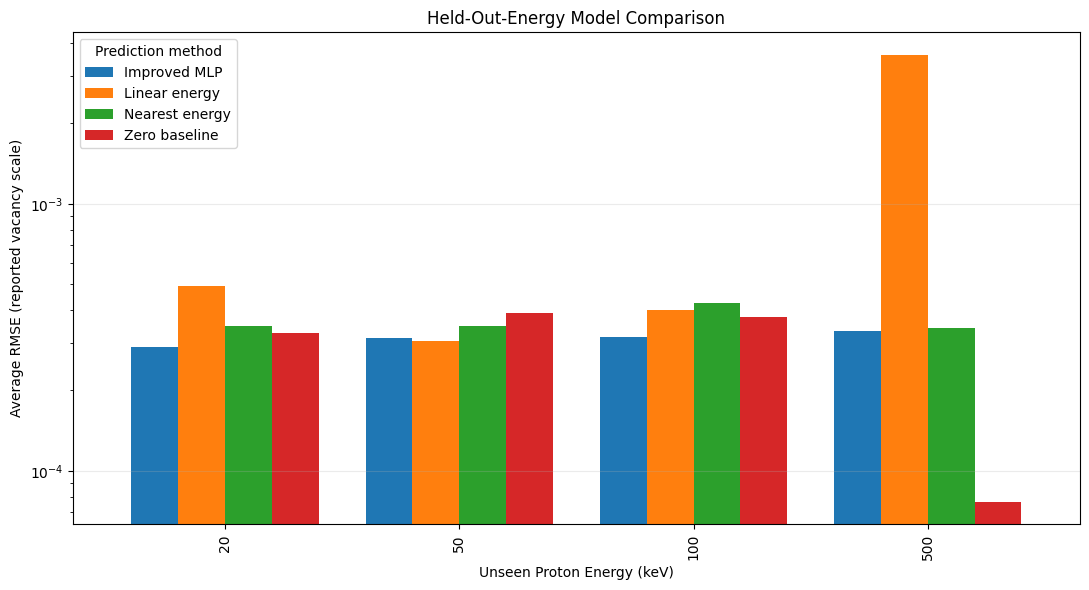


FRACTION OF NEGATIVE PREDICTIONS


model
Improved MLP      0.0000
Linear energy     0.1866
Nearest energy    0.0017
Zero baseline     0.0000
Name: negative_fraction, dtype: float64


SELECTED TRAINING EPOCHS


seed,42,43,44,45,46
energy_keV,,,,,
20,2,2,2,1,2
50,2,1,2,1,2
100,9,34,9,8,8
500,22,34,15,131,20


In [10]:

# Average scores across five random seeds
summary = (
    results_df
    .groupby(["energy_keV", "model"])[["RMSE", "MAE", "R2"]]
    .mean()
    .reset_index()
)

print("MODEL PERFORMANCE BY ENERGY")
display(
    summary.pivot(
        index="energy_keV",
        columns="model",
        values="RMSE"
    ).round(8)
)

# Identify the best model for each energy/species/material
detailed = (
    results_df
    .groupby(["energy_keV", "material", "species", "model"])[
        ["RMSE", "MAE", "R2"]
    ]
    .mean()
    .reset_index()
)

winners = detailed.loc[
    detailed.groupby(
        ["energy_keV", "material", "species"]
    )["RMSE"].idxmin()
]

print("\nBEST METHOD FOR EACH TEST CONDITION")
display(
    winners[
        ["energy_keV", "material", "species", "model", "RMSE"]
    ].sort_values(
        ["energy_keV", "material", "species"]
    )
)

# RMSE comparison
rmse_table = summary.pivot(
    index="energy_keV",
    columns="model",
    values="RMSE"
)

ax = rmse_table.plot(
    kind="bar",
    figsize=(11, 6),
    width=0.8
)

ax.set_title("Held-Out-Energy Model Comparison")
ax.set_xlabel("Unseen Proton Energy (keV)")
ax.set_ylabel("Average RMSE (reported vacancy scale)")
ax.set_yscale("log")
ax.legend(title="Prediction method")
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.savefig(
    "Abiha_Experiment2_Model_Comparison.png",
    dpi=300,
    bbox_inches="tight"
)
plt.show()

# Check negative predictions
print("\nFRACTION OF NEGATIVE PREDICTIONS")
display(
    results_df
    .groupby("model")["negative_fraction"]
    .mean()
    .round(4)
)

# Inspect training duration
print("\nSELECTED TRAINING EPOCHS")
display(
    results_df[
        results_df["model"] == "Improved MLP"
    ]
    .groupby(["energy_keV", "seed"])["best_epoch"]
    .first()
    .unstack()
)


In [11]:

original = pd.read_csv("Abiha_heldout_metrics.csv")

original = original[
    original["method"] == "MLP"
].copy()

original = original.rename(
    columns={"test_energy_keV": "energy_keV"}
)

old_scores = original.groupby(
    ["energy_keV", "material", "species"]
)["RMSE"].mean().rename("Original_MLP_RMSE")

new_scores = results_df[
    results_df["model"] == "Improved MLP"
].groupby(
    ["energy_keV", "material", "species"]
)["RMSE"].mean().rename("Improved_MLP_RMSE")

comparison = pd.concat(
    [old_scores, new_scores],
    axis=1
)

comparison["RMSE_Change_Percent"] = (
    (comparison["Improved_MLP_RMSE"]
     - comparison["Original_MLP_RMSE"])
    / comparison["Original_MLP_RMSE"]
    * 100
)

comparison["Improved"] = (
    comparison["RMSE_Change_Percent"] < 0
)

display(comparison.round(7))

print(
    "\nConditions improved:",
    comparison["Improved"].sum(),
    "out of",
    len(comparison)
)

comparison.to_csv(
    "Abiha_Original_vs_Improved_MLP.csv"
)


Original_MLP_RMSE  Improved_MLP_RMSE  \
energy_keV material species                                         
20         Cs3Sb2I9 vac_B             0.000124           0.000132   
                    vac_Cs            0.000185           0.000183   
                    vac_I             0.000537           0.000513   
           CsPbI3   vac_B             0.000179           0.000177   
                    vac_Cs            0.000249           0.000196   
                    vac_I             0.000481           0.000541   
50         Cs3Sb2I9 vac_B             0.000112           0.000134   
                    vac_Cs            0.000166           0.000203   
                    vac_I             0.000482           0.000553   
           CsPbI3   vac_B             0.000170           0.000196   
                    vac_Cs            0.000178           0.000214   
                    vac_I             0.000533           0.000590   
100        Cs3Sb2I9 vac_B             0.000151           0.000126   
                    vac_Cs            0.000225           0.000193   
                    vac_I             0.000662           0.000552   
           CsPbI3   vac_B             0.000219           0.000195   
                    vac_Cs            0.000524           0.000500   
                    vac_I             0.000417           0.000331   
500        Cs3Sb2I9 vac_B             0.000442           0.000108   
                    vac_Cs            0.000515           0.000323   
                    vac_I             0.002053           0.000266   
           CsPbI3   vac_B             0.000437           0.000203   
                    vac_Cs            0.000752           0.001005   
                    vac_I             0.002674           0.000096   

                             RMSE_Change_Percent  Improved  
energy_keV material species                                 
20         Cs3Sb2I9 vac_B               6.307292     False  
                    vac_Cs             -1.390077      True  
                    vac_I              -4.569591      True  
           CsPbI3   vac_B              -1.252833      True  
                    vac_Cs            -21.140546      True  
                    vac_I              12.526317     False  
50         Cs3Sb2I9 vac_B              19.766468     False  
                    vac_Cs             22.754189     False  
                    vac_I              14.742949     False  
           CsPbI3   vac_B              15.272257     False  
                    vac_Cs             20.770429     False  
                    vac_I              10.745068     False  
100        Cs3Sb2I9 vac_B             -16.553586      True  
                    vac_Cs            -14.071270      True  
                    vac_I             -16.603020      True  
           CsPbI3   vac_B             -10.879311      True  
                    vac_Cs             -4.474210      True  
                    vac_I             -20.721411      True  
500        Cs3Sb2I9 vac_B             -75.467555      True  
                    vac_Cs            -37.255657      True  
                    vac_I             -87.052762      True  
           CsPbI3   vac_B             -53.534884      True  
                    vac_Cs             33.576281     False  
                    vac_I             -96.395062      True


Conditions improved: 15 out of 24


In [12]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

TARGETS = ["vac_Cs", "vac_B", "vac_I"]
ENERGIES = [20, 50, 100, 500]
MATERIALS = ["CsPbI3", "Cs3Sb2I9"]

profile_results = []

for material in MATERIALS:
    for energy in ENERGIES:

        subset = df[
            (df["material"] == material) &
            (df["energy_keV"] == energy)
        ].sort_values("depth_angstrom")

        for species in TARGETS:
            z = subset["depth_angstrom"].to_numpy()
            v = subset[species].to_numpy()

            peak_index = np.argmax(v)

            profile_results.append({
                "material": material,
                "energy_keV": energy,
                "species": species,
                "peak_vacancy": v[peak_index],
                "peak_depth_angstrom": z[peak_index],
                "mean_vacancy": np.mean(v),
                "maximum_depth_angstrom": z.max()
            })

profile_summary = pd.DataFrame(profile_results)

display(profile_summary.round(8))

profile_summary.to_csv(
    "Abiha_Experiment3_Profile_Descriptors.csv",
    index=False
)


,material,energy_keV,species,peak_vacancy,peak_depth_angstrom,mean_vacancy,maximum_depth_angstrom
0,CsPbI3,20,vac_Cs,0.000663,900.01,0.000085,10000.00
1,CsPbI3,20,vac_B,0.000654,700.01,0.000078,10000.00
2,CsPbI3,20,vac_I,0.001926,900.01,0.000243,10000.00
3,CsPbI3,50,vac_Cs,0.000584,2000.01,0.000139,10000.00
4,CsPbI3,50,vac_B,0.000580,2400.01,0.000134,10000.00
5,CsPbI3,50,vac_I,0.001651,2500.01,0.000401,10000.00
6,CsPbI3,100,vac_Cs,0.001268,5100.01,0.000412,9600.01
7,CsPbI3,100,vac_B,0.000509,4300.01,0.000193,9600.01
8,CsPbI3,100,vac_I,0.000538,4800.01,0.000191,9600.01
9,CsPbI3,500,vac_Cs,0.000115,5400.01,0.000045,10000.00


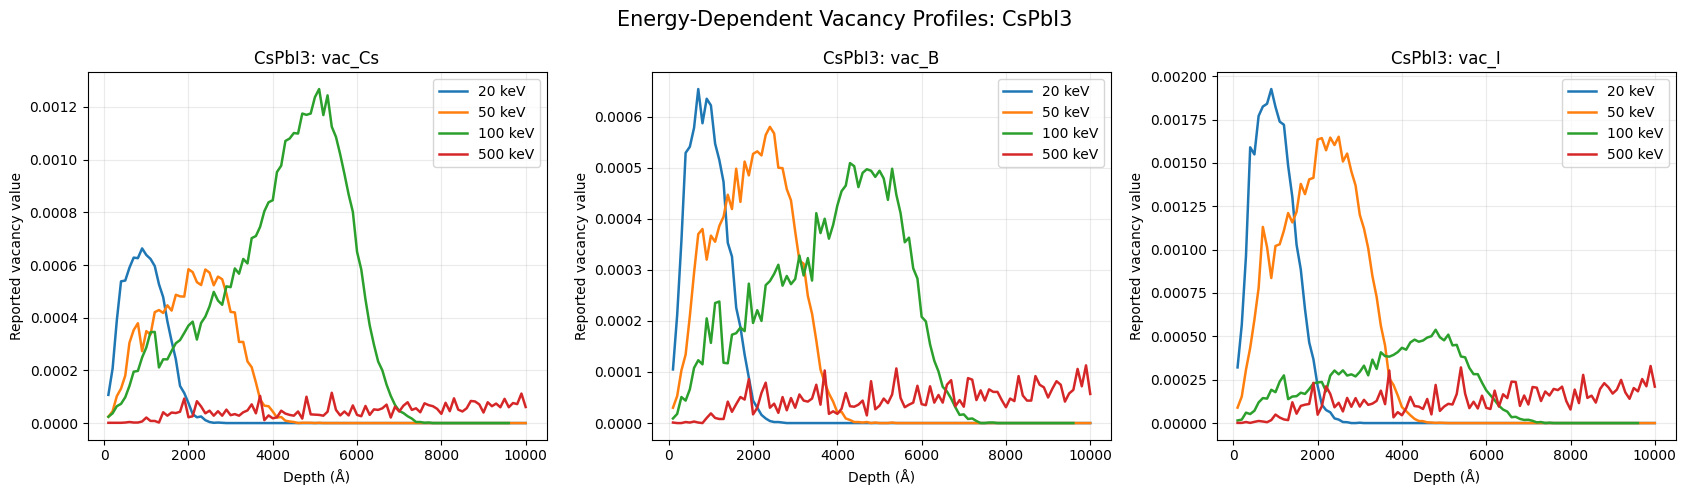

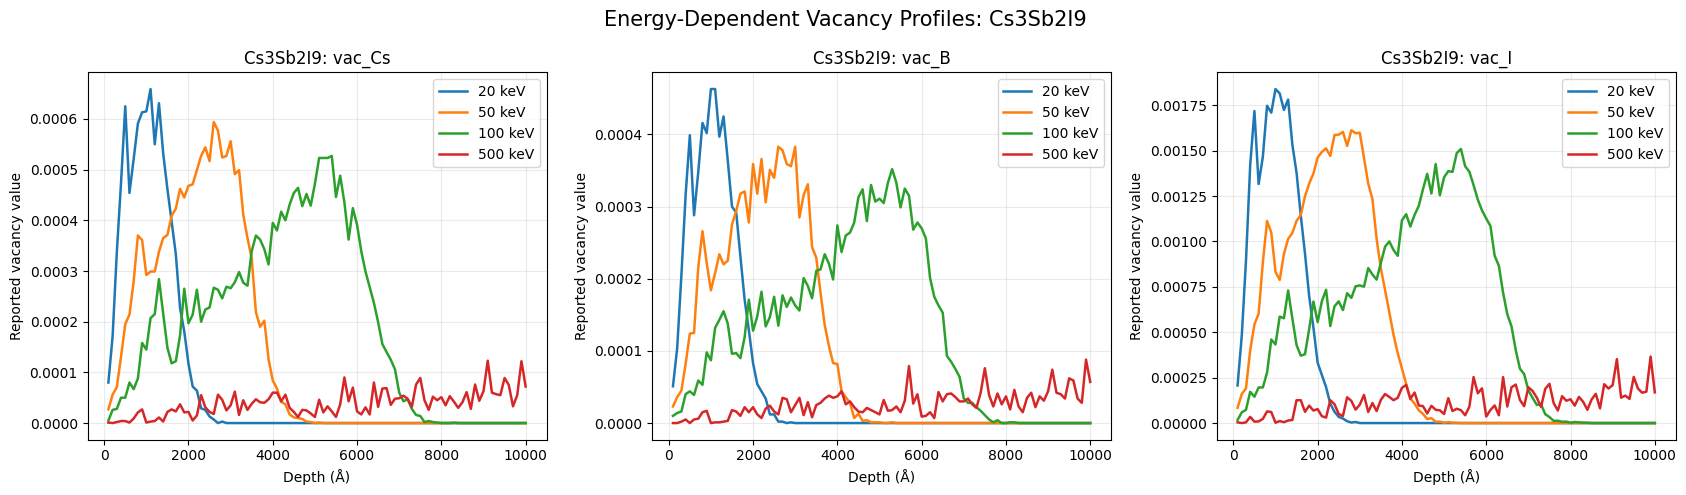

In [13]:

for material in MATERIALS:

    fig, axes = plt.subplots(
        1, 3,
        figsize=(17, 5)
    )

    for i, species in enumerate(TARGETS):
        ax = axes[i]

        for energy in ENERGIES:
            subset = df[
                (df["material"] == material) &
                (df["energy_keV"] == energy)
            ].sort_values("depth_angstrom")

            ax.plot(
                subset["depth_angstrom"],
                subset[species],
                label=f"{energy} keV",
                linewidth=1.8
            )

        ax.set_title(f"{material}: {species}")
        ax.set_xlabel("Depth (Å)")
        ax.set_ylabel("Reported vacancy value")
        ax.legend()
        ax.grid(alpha=0.25)

    plt.suptitle(
        f"Energy-Dependent Vacancy Profiles: {material}",
        fontsize=15
    )

    plt.tight_layout()

    plt.savefig(
        f"Abiha_Experiment3_Profiles_{material}.png",
        dpi=300,
        bbox_inches="tight"
    )

    plt.show()


In [14]:

from scipy.interpolate import interp1d
from sklearn.metrics import mean_squared_error, mean_absolute_error, r2_score

def interpolate_profile(train, material, energy, depths):
    subset = train[
        (train["material"] == material) &
        (train["energy_keV"] == energy)
    ].sort_values("depth_angstrom")

    f = interp1d(
        subset["depth_angstrom"].to_numpy(),
        subset[TARGETS].to_numpy(),
        axis=0,
        bounds_error=False,
        fill_value=np.nan
    )

    return f(depths)


def energy_baselines(train, test):
    n = len(test)

    linear = np.full((n, 3), np.nan)
    log_energy = np.full((n, 3), np.nan)
    zero = np.zeros((n, 3))

    for material in MATERIALS:

        indices = np.flatnonzero(
            (test["material"] == material).to_numpy()
        )

        if len(indices) == 0:
            continue

        subset = test.iloc[indices]
        E = float(subset["energy_keV"].iloc[0])
        depths = subset["depth_angstrom"].to_numpy()

        available = sorted(
            train.loc[
                train["material"] == material,
                "energy_keV"
            ].unique()
        )

        if E < available[0]:
            E1, E2 = available[:2]
        elif E > available[-1]:
            E1, E2 = available[-2:]
        else:
            E1 = max(x for x in available if x < E)
            E2 = min(x for x in available if x > E)

        y1 = interpolate_profile(
            train, material, E1, depths
        )

        y2 = interpolate_profile(
            train, material, E2, depths
        )

        # Original linear-energy baseline
        w_linear = (E - E1) / (E2 - E1)

        linear[indices] = (
            y1 + w_linear * (y2 - y1)
        )

        # Logarithmic-energy baseline
        w_log = (
            (np.log10(E) - np.log10(E1)) /
            (np.log10(E2) - np.log10(E1))
        )

        log_energy[indices] = (
            y1 + w_log * (y2 - y1)
        )

    return {
        "Linear energy": linear,
        "Log energy": log_energy,
        "Zero baseline": zero
    }


experiment3_results = []

for held_out in ENERGIES:

    train = df[
        df["energy_keV"] != held_out
    ].copy()

    test = df[
        df["energy_keV"] == held_out
    ].copy().reset_index(drop=True)

    baseline_predictions = energy_baselines(train, test)

    actual = test[TARGETS].to_numpy()

    for material in MATERIALS:
        material_mask = (
            test["material"] == material
        ).to_numpy()

        for k, species in enumerate(TARGETS):

            # Compare on common supported depths
            valid = material_mask.copy()

            for prediction in baseline_predictions.values():
                valid &= np.isfinite(prediction[:, k])

            y_true = actual[valid, k]

            for method, prediction in baseline_predictions.items():
                y_pred = prediction[valid, k]

                experiment3_results.append({
                    "energy_keV": held_out,
                    "material": material,
                    "species": species,
                    "method": method,
                    "n_evaluated": len(y_true),
                    "RMSE": np.sqrt(
                        mean_squared_error(y_true, y_pred)
                    ),
                    "MAE": mean_absolute_error(
                        y_true, y_pred
                    ),
                    "R2": r2_score(y_true, y_pred),
                    "negative_fraction": np.mean(y_pred < 0)
                })

experiment3_df = pd.DataFrame(experiment3_results)

display(
    experiment3_df.groupby(
        ["energy_keV", "method"]
    )[["RMSE", "MAE", "R2"]].mean().round(8)
)

experiment3_df.to_csv(
    "Abiha_Experiment3_Energy_Baselines.csv",
    index=False
)

print("Experiment 3 completed.")


RMSE       MAE            R2
energy_keV method                                         
20         Linear energy  0.000490  0.000322     -1.757292
           Log energy     0.000748  0.000502     -5.981863
           Zero baseline  0.000329  0.000138     -0.210843
50         Linear energy  0.000306  0.000201      0.039292
           Log energy     0.000322  0.000216     -0.155203
           Zero baseline  0.000390  0.000227     -0.511763
100        Linear energy  0.000402  0.000281     -2.284626
           Log energy     0.000366  0.000250     -1.454811
           Zero baseline  0.000378  0.000279     -1.223207
500        Linear energy  0.003616  0.002532 -11215.898761
           Log energy     0.001215  0.000832  -1389.073220
           Zero baseline  0.000076  0.000065     -2.683113

Experiment 3 completed.


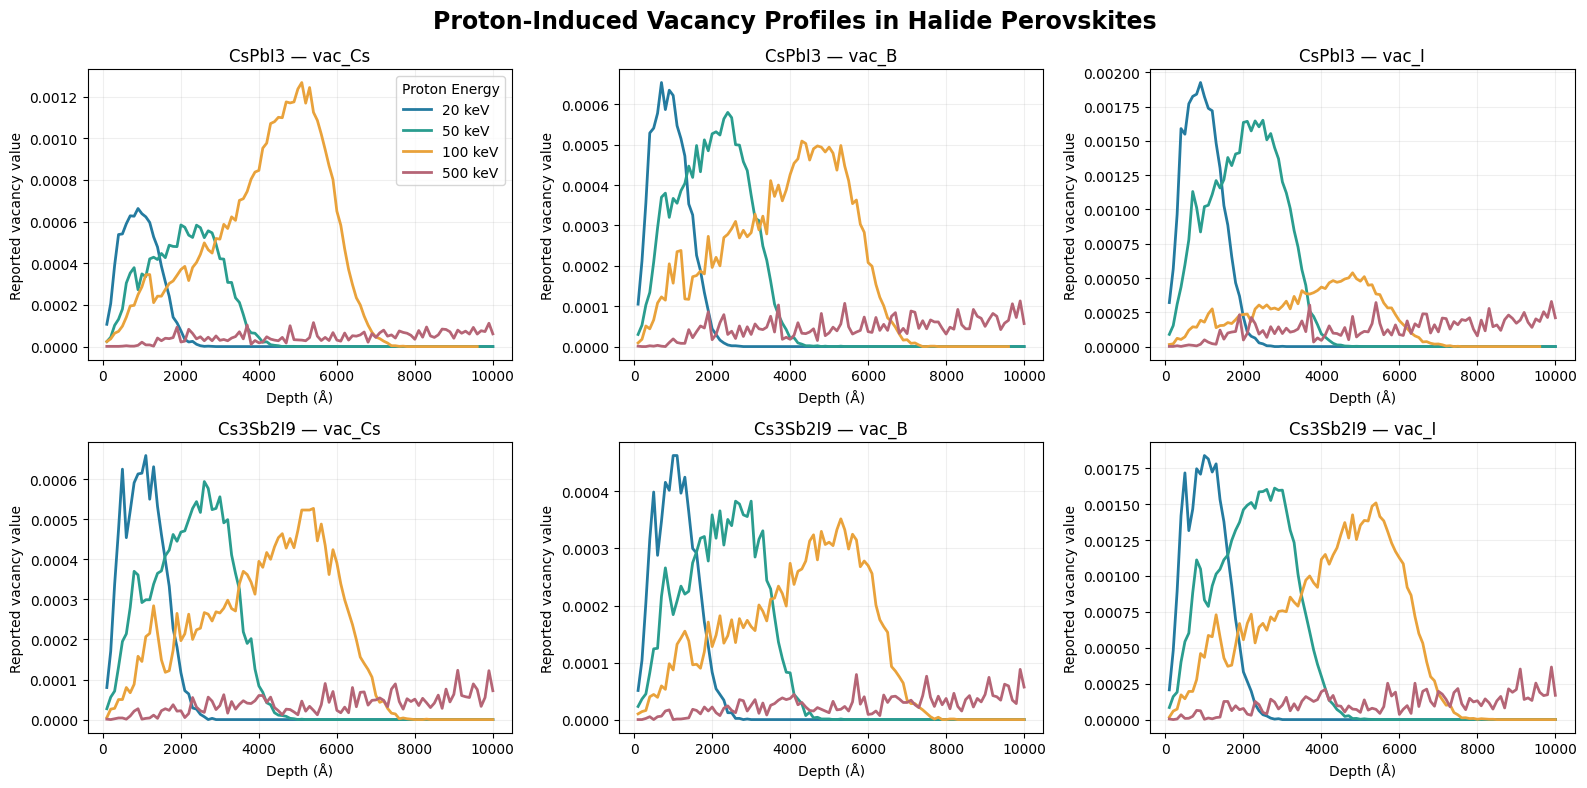

In [15]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

materials = ["CsPbI3", "Cs3Sb2I9"]
energies = [20, 50, 100, 500]
species = ["vac_Cs", "vac_B", "vac_I"]

colors = {
    20: "#247BA0",
    50: "#2A9D8F",
    100: "#E9A23B",
    500: "#B56576"
}

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for i, material in enumerate(materials):
    for j, vacancy in enumerate(species):

        ax = axes[i, j]

        for energy in energies:
            subset = df[
                (df["material"] == material) &
                (df["energy_keV"] == energy)
            ].sort_values("depth_angstrom")

            ax.plot(
                subset["depth_angstrom"],
                subset[vacancy],
                linewidth=2,
                color=colors[energy],
                label=f"{energy} keV"
            )

        ax.set_title(f"{material} — {vacancy}", fontsize=12)
        ax.set_xlabel("Depth (Å)")
        ax.set_ylabel("Reported vacancy value")
        ax.grid(alpha=0.2)

axes[0, 0].legend(title="Proton Energy")

fig.suptitle(
    "Proton-Induced Vacancy Profiles in Halide Perovskites",
    fontsize=17,
    fontweight="bold"
)

plt.tight_layout()
plt.savefig("Figure1_Vacancy_Profiles.png", dpi=300, bbox_inches="tight")
plt.show()



### Figure 1. Energy-Dependent Vacancy-Depth Distributions

The radiation-induced vacancy profiles were analyzed for CsPbI₃ and Cs₃Sb₂I₉ at proton energies of 20, 50, 100, and 500 keV.

Three vacancy species were examined: Cs vacancies, B-site vacancies (Pb or Sb), and iodine vacancies.

**Key observations:**

1. Vacancy distributions exhibit strong depth dependence, with identifiable regions of maximum reported vacancy generation.
2. Increasing proton energy generally shifts the vacancy peaks toward greater depths.
3. The profiles exhibit changes in both peak magnitude and shape, indicating that their energy dependence cannot always be represented by simple amplitude scaling.
4. At 500 keV, several reported vacancy maxima occur close to the maximum recorded depth of 10,000 Å.

**Scientific interpretation:**

The observed peak-depth migration is consistent with increasing proton penetration depth at higher incident energies.

However, the proximity of several 500 keV maxima to the recorded depth boundary raises the possibility of incomplete profile coverage.

Consequently, lower recorded vacancy values at 500 keV cannot, by themselves, establish reduced total radiation damage.

The simulation normalization and completeness of the high-energy depth profiles require verification.


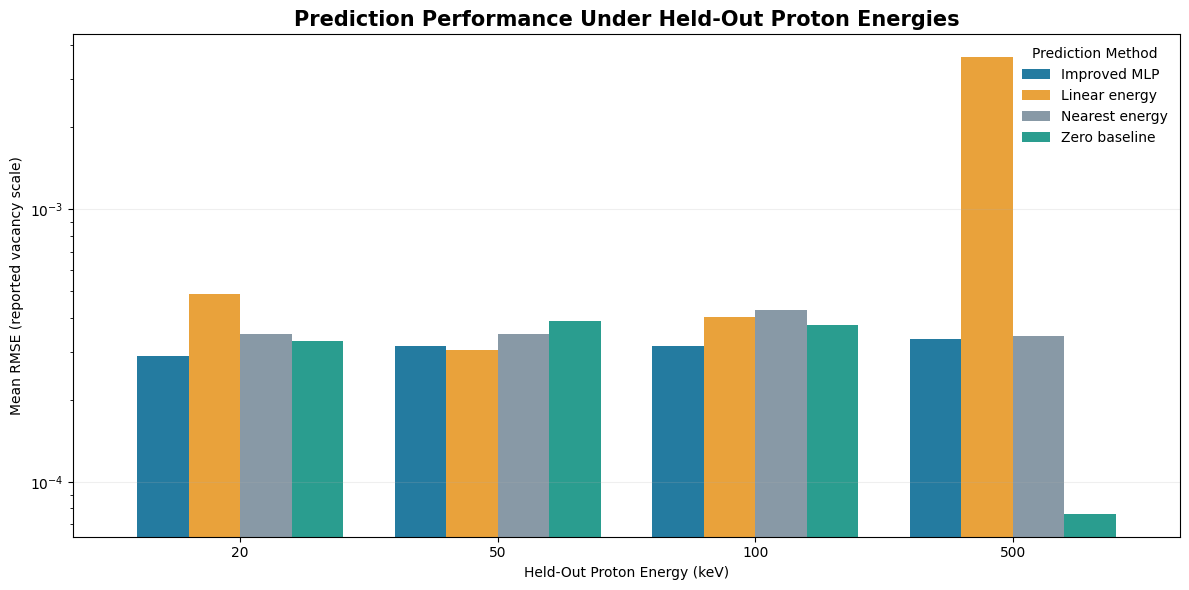

In [16]:

comparison = (
    results_df
    .groupby(["energy_keV", "model"])["RMSE"]
    .mean()
    .unstack()
)

model_order = [
    "Improved MLP",
    "Linear energy",
    "Nearest energy",
    "Zero baseline"
]

ax = comparison[model_order].plot(
    kind="bar",
    figsize=(12, 6),
    width=0.8,
    color=[
        "#247BA0",
        "#E9A23B",
        "#8899A6",
        "#2A9D8F"
    ]
)

ax.set_title(
    "Prediction Performance Under Held-Out Proton Energies",
    fontsize=15,
    fontweight="bold"
)

ax.set_xlabel("Held-Out Proton Energy (keV)")
ax.set_ylabel("Mean RMSE (reported vacancy scale)")
ax.set_yscale("log")
ax.legend(title="Prediction Method", frameon=False)
ax.grid(axis="y", alpha=0.2)

plt.xticks(rotation=0)
plt.tight_layout()

plt.savefig(
    "Figure2_Model_Performance.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### Figure 2. Generalization Performance of the MLP and Baseline Methods

Model performance was evaluated using a leave-one-energy-out procedure. For each experiment, both materials at one proton energy were excluded from training.

The improved MLP was compared against three baseline methods:

- Linear-energy interpolation or extrapolation
- Nearest-energy profile prediction
- Zero-vacancy prediction

Five random seeds were used to examine variability in neural-network training.

**Key results:**

| Held-out energy | Improved MLP RMSE | Linear-energy RMSE | Zero-baseline RMSE |
|---|---:|---:|---:|
| 20 keV | 0.000290 | 0.000490 | 0.000329 |
| 50 keV | 0.000315 | 0.000306 | 0.000390 |
| 100 keV | 0.000316 | 0.000402 | 0.000378 |
| 500 keV | 0.000334 | 0.003616 | 0.000076 |

**Interpretation:**

The improved MLP demonstrated competitive performance at 20 and 100 keV.

However, the linear-energy baseline achieved slightly lower average error at 50 keV.

At 500 keV, the zero-vacancy baseline substantially outperformed the neural network.

Although the improved MLP reduced the original model's mean 500 keV RMSE by approximately 71%, its error remained approximately 4.4 times higher than the zero-vacancy baseline.

**Scientific significance:**

These results demonstrate that outperforming a conventional interpolation method does not necessarily establish reliable machine-learning generalization.

The findings highlight the importance of evaluating neural networks against multiple simple baselines, particularly when working with limited simulation datasets.

Because later model variants were developed after examining earlier held-out results, these comparisons should be considered exploratory rather than independent confirmation of predictive superiority.



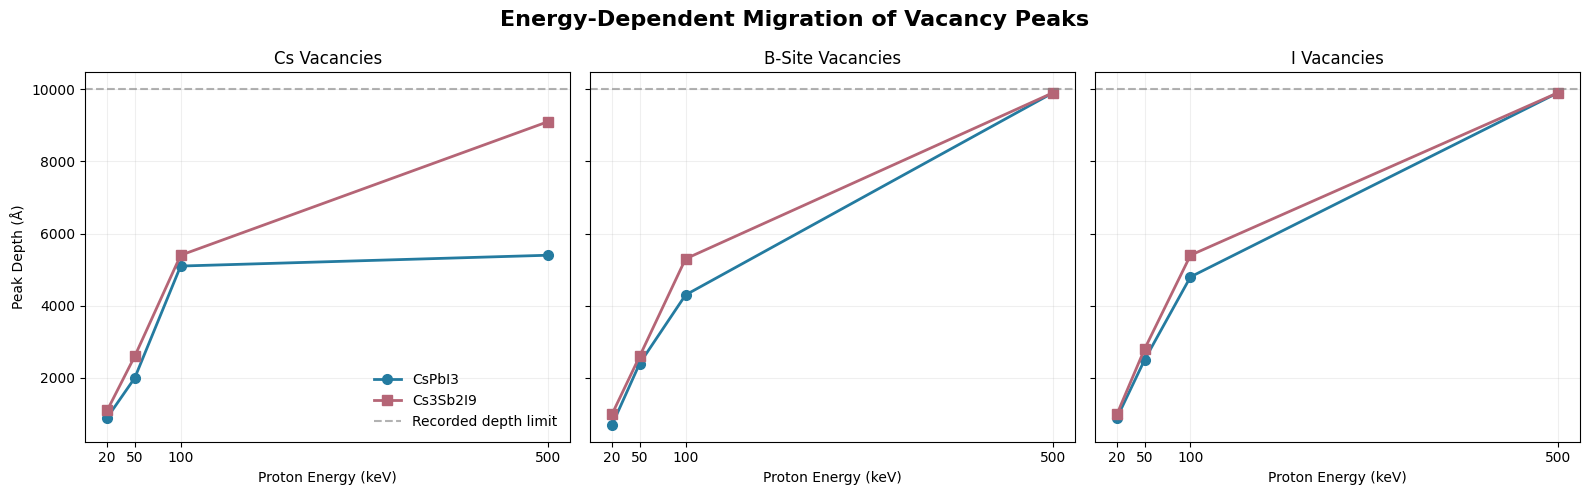

In [17]:

fig, axes = plt.subplots(1, 3, figsize=(16, 5), sharey=True)

species_labels = {
    "vac_Cs": "Cs Vacancies",
    "vac_B": "B-Site Vacancies",
    "vac_I": "I Vacancies"
}

for j, vacancy in enumerate(species):

    ax = axes[j]

    for material, color, marker in [
        ("CsPbI3", "#247BA0", "o"),
        ("Cs3Sb2I9", "#B56576", "s")
    ]:

        subset = profile_summary[
            (profile_summary["material"] == material) &
            (profile_summary["species"] == vacancy)
        ].sort_values("energy_keV")

        ax.plot(
            subset["energy_keV"],
            subset["peak_depth_angstrom"],
            marker=marker,
            markersize=7,
            linewidth=2,
            color=color,
            label=material
        )

    ax.axhline(
        10000,
        color="gray",
        linestyle="--",
        alpha=0.6,
        label="Recorded depth limit"
    )

    ax.set_title(species_labels[vacancy])
    ax.set_xlabel("Proton Energy (keV)")
    ax.set_xticks(energies)
    ax.grid(alpha=0.2)

axes[0].set_ylabel("Peak Depth (Å)")
axes[0].legend(frameon=False)

fig.suptitle(
    "Energy-Dependent Migration of Vacancy Peaks",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "Figure3_Peak_Depth_Migration.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### Figure 3. Energy Dependence of Vacancy Peak Depth

The depth corresponding to the maximum reported vacancy value was extracted for each vacancy species, material, and proton energy.

**Iodine-vacancy peak positions:**

| Energy | CsPbI₃ | Cs₃Sb₂I₉ |
|---|---:|---:|
| 20 keV | 900.01 Å | 1,000.01 Å |
| 50 keV | 2,500.01 Å | 2,800.01 Å |
| 100 keV | 4,800.01 Å | 5,400.01 Å |
| 500 keV | 9,900.01 Å | 9,900.01 Å |

**Key observations:**

1. Iodine-vacancy peak depth increases with proton energy in both materials.
2. Cs₃Sb₂I₉ exhibits deeper iodine-vacancy maxima than CsPbI₃ at 20, 50, and 100 keV.
3. At 500 keV, both iodine-vacancy peaks approach the recorded depth boundary.
4. Not all vacancy species exhibit identical peak-depth behavior.

**Scientific significance:**

The systematic migration of vacancy maxima suggests that the depth distribution is an important component of the radiation response.

A predictive model must therefore reproduce both vacancy magnitudes and their spatial distributions.

The 500 keV results require particular caution because the reported maximum may be constrained by the available simulation depth window.

These observations motivate further analysis of depth-dependent radiation damage rather than relying exclusively on aggregate prediction metrics.


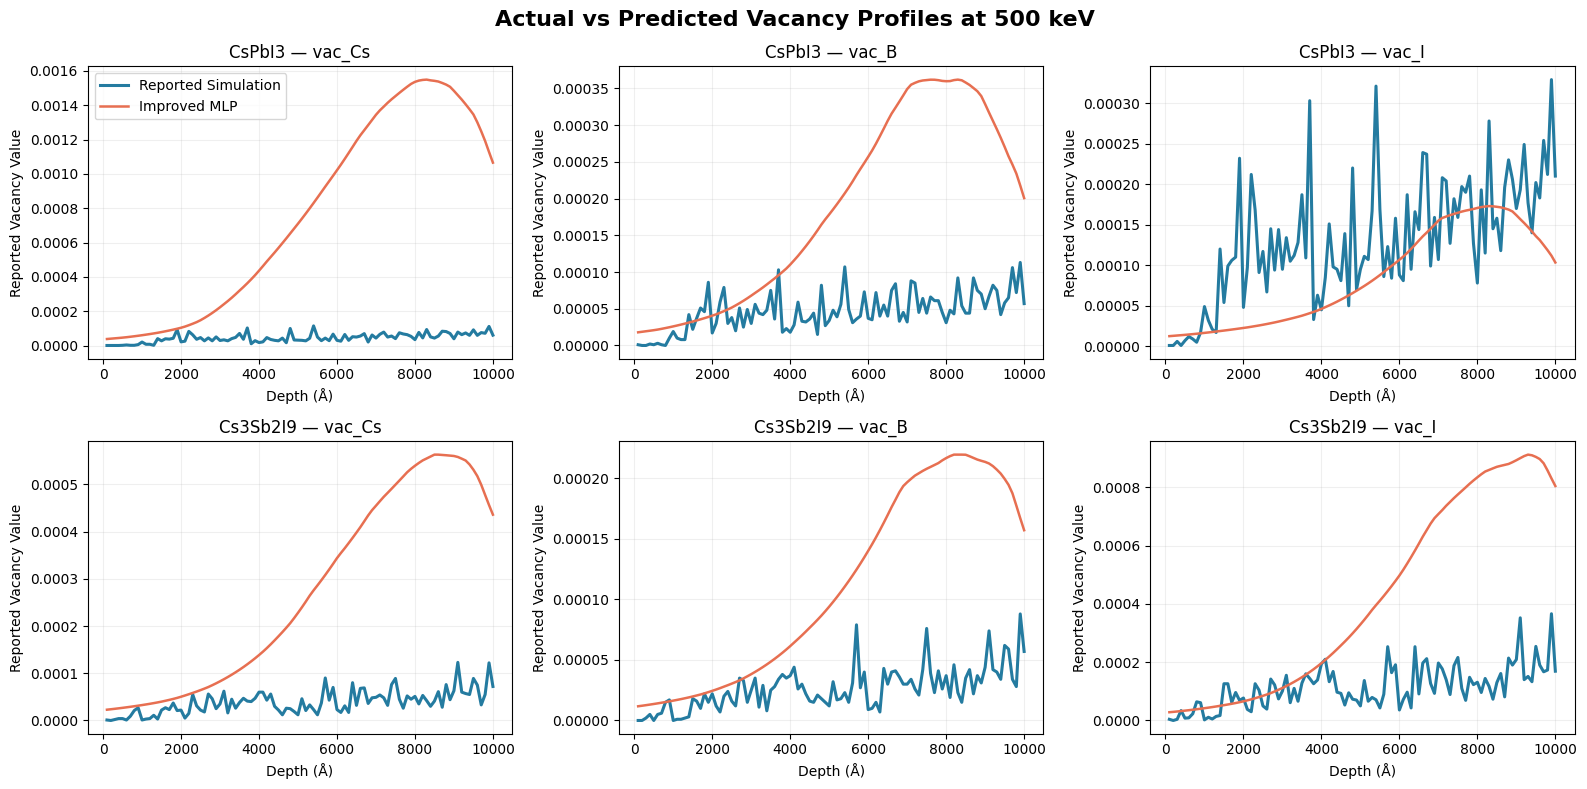

In [18]:

fig, axes = plt.subplots(2, 3, figsize=(16, 8))

for i, material in enumerate(materials):

    subset = predictions_df[
        (predictions_df["material"] == material) &
        (predictions_df["energy_keV"] == 500) &
        (predictions_df["seed"] == 42)
    ].sort_values("depth_angstrom")

    for j, vacancy in enumerate(species):

        ax = axes[i, j]

        ax.plot(
            subset["depth_angstrom"],
            subset[f"{vacancy}_actual"],
            linewidth=2.2,
            color="#247BA0",
            label="Reported Simulation"
        )

        ax.plot(
            subset["depth_angstrom"],
            subset[f"{vacancy}_Improved_MLP"],
            linewidth=1.8,
            color="#E76F51",
            label="Improved MLP"
        )

        ax.set_title(f"{material} — {vacancy}")
        ax.set_xlabel("Depth (Å)")
        ax.set_ylabel("Reported Vacancy Value")
        ax.grid(alpha=0.2)

axes[0, 0].legend()

fig.suptitle(
    "Actual vs Predicted Vacancy Profiles at 500 keV",
    fontsize=16,
    fontweight="bold"
)

plt.tight_layout()

plt.savefig(
    "Figure4_500keV_Predictions.png",
    dpi=300,
    bbox_inches="tight"
)

plt.show()



### Figure 4. High-Energy Extrapolation of Vacancy Profiles

The improved MLP predictions were compared with the reported simulation profiles at the held-out proton energy of 500 keV.

The displayed predictions correspond to random seed 42, while the quantitative evaluation incorporates five random seeds.

**Key observations:**

1. The improved MLP produces nonnegative vacancy predictions because of its Softplus output activation.
2. Despite this physical constraint, substantial differences remain between predicted and reported vacancy distributions.
3. Predictive errors vary across vacancy species and materials.
4. The model does not consistently reproduce the low reported vacancy magnitudes at 500 keV.

**Scientific interpretation:**

The poor high-energy extrapolation indicates that relationships learned from lower proton energies are insufficient to reconstruct the reported 500 keV profiles accurately.

This limitation may arise from nonlinear changes in vacancy generation, shifting depth distributions, incomplete high-energy profile coverage, or insufficient independent training profiles.

The available results cannot distinguish these explanations conclusively.

**Research implication:**

Reliable prediction across a wider energy range may require additional independent simulation profiles, improved physical representation of radiation-induced damage, and explicit consideration of the depth-dependent structure of vacancy distributions.



## Consolidated Findings and Research Implications

Three computational experiments were conducted to investigate proton-induced vacancy distributions in CsPbI₃ and Cs₃Sb₂I₉.

### 1. Machine-Learning Performance

The original multi-output MLP was evaluated using complete held-out proton energies rather than random depth-wise splitting.

An improved model incorporating logarithmic energy preprocessing and nonnegative output activation reduced the original model's RMSE in 15 of 24 material–energy–vacancy comparisons.

Nevertheless, no single model consistently outperformed all baseline methods across the investigated energy range.

### 2. High-Energy Generalization

Prediction at 500 keV remained particularly challenging.

Although the improved MLP substantially reduced the original model's error, the zero-vacancy baseline achieved considerably better performance.

This demonstrates a limitation of extrapolating from a small number of available radiation-energy profiles.

### 3. Physical Vacancy Distributions

Vacancy maxima generally migrated toward greater depths with increasing proton energy.

At 500 keV, several maxima occurred close to the maximum recorded depth, suggesting possible truncation of the exported profiles.

Peak vacancy magnitudes also exhibited non-monotonic energy dependence in some cases.

### 4. Scientific Limitations

The dataset comprises eight material–energy profiles, with correlated observations along depth.

The original simulation normalization, incident particle count or fluence, and completeness of the high-energy profiles remain unverified.

Therefore, the current results do not establish absolute vacancy concentrations, overall radiation-hardness rankings, or photovoltaic device lifetimes.

### 5. Conclusion

The study demonstrates both the potential and limitations of machine-learning reconstruction of radiation-induced vacancy profiles from a small simulation dataset.

While the improved MLP offers better performance under several held-out conditions, its failure to outperform simple baselines consistently highlights the need for stronger physical constraints, independent validation, and additional radiation-energy profiles.

The identified energy-dependent changes in vacancy magnitude and peak depth provide a foundation for further physical interpretation and comparison of the two investigated materials.

The next research stage will integrate these findings with independent electronic, thermodynamic-stability, and literature evidence to prioritize additional lead-free halide perovskite candidates for future radiation studies.
